# W12A A · 축제 오프닝 사운드 만들기

11월 16일 · 주교재 9장 실습. 두 소리 중 어느 쪽이 문장을 반복하나요? 먼저 듣고, 그림에서 근거를 찾은 뒤 직접 코드를 바꿉니다.

Colab에서는 새 사본에서 첫 셀부터 실행하세요. 오디오를 들을 때는 재생 버튼을 누르세요. 연결이 아직 되지 않았다면 [안내 음성 A](https://cdn.jsdelivr.net/gh/lunalab-ai/genAI@2026-fall-w12a/src/luna_genai/assets/w12a/voice-a.wav)와 [안내 음성 B](https://cdn.jsdelivr.net/gh/lunalab-ai/genAI@2026-fall-w12a/src/luna_genai/assets/w12a/voice-b.wav)를 새 탭에서 바로 들을 수 있습니다. 학생 ZIP을 받았다면 압축을 풀고 `course/notion/w12a/listen.html`을 브라우저에서 여세요.


In [ ]:
from pathlib import Path
from urllib.request import urlopen
from IPython.display import Audio, display

base = "https://cdn.jsdelivr.net/gh/lunalab-ai/genAI@2026-fall-w12a/src/luna_genai/assets/w12a/"
for name, label in [("voice-a.wav", "안내 A"), ("voice-b.wav", "안내 B")]:
    path = Path("src/luna_genai/assets/w12a") / name
    if path.is_file():
        data = path.read_bytes()
    else:
        with urlopen(base + name, timeout=20) as response:
            data = response.read()
    print("사전 생성 · " + label)
    display(Audio(data=data, embed=True))


## 1. 높낮이를 바꾸는 줄과 그림만 바꾸는 줄

$f$는 1초에 몇 번 진동하는지 나타냅니다. 이 효과음은 기본주파수 $f$와 두 번째 배음 $2f$를 섞습니다. 재생 시간은 그대로 두고 `frequency`만 두 배로 바꾸면 스펙트로그램의 밝은 띠는 어디로 이동할까요?

STFT는 소리를 짧은 구간으로 나누어 각 구간의 주파수 성분을 계산합니다. 창 길이와 창을 옮기는 간격(hop)을 따로 조절합니다. 로그 멜 그림은 Hz 구간들을 멜 대역으로 묶어 보여 줍니다.


In [ ]:
#@title 수업 패키지 설치 { display-mode: "form" }
import os, sys, subprocess, json
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
from IPython.display import Audio, Image, display

PUBLIC_REF = "2026-fall-w12a"
SOURCE = Path("src").resolve()
local = (SOURCE / "pyproject.toml").is_file()
try:
    ready = version("luna-genai") == "0.1.21" and version("librosa") == "1.0.0"
except PackageNotFoundError:
    ready = False
if not ready:
    if "luna_genai" in sys.modules:
        raise RuntimeError("런타임을 재시작한 뒤 첫 셀부터 실행하세요.")
    spec = str(SOURCE) + "[audio]" if local else (
        "luna-genai[audio] @ " + "git+https://github.com/lunalab-ai/genAI.git@"
        + PUBLIC_REF + "#subdirectory=src"
    )
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)
if local:
    sys.path.insert(0, str(SOURCE))
import numpy as np
from io import BytesIO
from luna_genai.sound_studio import lesson_assets
ASSET = lesson_assets()
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

def show_plot(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=125, facecolor="white")
        data = buffer.getvalue()
    assert data.startswith(bytes.fromhex("89504e470d0a1a0a"))
    display(Image(data=data, format="png"))

print("Python", sys.version.split()[0], "· luna-genai", version("luna-genai"))


In [ ]:
import base64, torch
from tempfile import mkdtemp
from IPython.display import HTML
from luna_genai.sound_studio import read_wav, write_wav, sound_figure, build_studio
from luna_genai.sound_studio import SPEECH_TEXT, MUSIC_MODEL, MUSIC_REVISION, load_music
torch.set_num_threads(4)
outputs = Path(mkdtemp(prefix="w12a-audio-"))


In [ ]:
def festival_tone(frequency=440, overtone=.25, sampling_rate=16000):
    """Make a three-second, gated two-sine logo with the same envelope for A/B."""
    frequency, overtone = float(frequency), float(overtone)
    if not 80 <= frequency <= 1800 or not 0 <= overtone <= 1:
        raise ValueError("Use 80–1800 Hz and an overtone weight of 0–1.")
    time = np.arange(3 * sampling_rate) / sampling_rate
    phase = 2 * np.pi * frequency * time
    envelope = np.where(time % 1 < .68, np.sin(np.pi * np.minimum(time % 1 / .68, 1)) ** 2, 0)
    signal = (np.sin(phase) + overtone * np.sin(2 * phase)) / (1 + overtone)
    return (0.60 * envelope * signal).astype(np.float32)

def classroom_stft(samples, rate, window=512, hop=128):
    """Center short Hann windows, then compute one-sided power at each frame."""
    if not 0 < hop <= window or window < 4 or len(samples) < window:
        raise ValueError("A window must fit the signal and cover its hop.")
    padded = np.pad(np.asarray(samples, dtype=np.float64), window // 2)
    frames = np.lib.stride_tricks.sliding_window_view(padded, window)[::hop]
    hann = np.hanning(window)
    spectrum = np.fft.rfft(frames * hann, axis=1) * (2 / hann.sum())
    power = np.abs(spectrum) ** 2
    times = np.arange(len(frames)) * hop / rate
    frequencies = np.fft.rfftfreq(window, d=1 / rate)
    return times, frequencies, power.T


In [ ]:
def present(title, name, samples, rate):
    path = Path(write_wav(outputs / name, samples, rate))
    played, fs = read_wav(path)
    print(title, "·", round(len(played)/fs,3), "s ·", fs, "Hz")
    display(Audio(filename=str(path), embed=True))
    data = base64.b64encode(path.read_bytes()).decode("ascii")
    display(HTML(f'<a href="data:audio/wav;base64,{data}" download="{name}">WAV 저장</a>'))
    return title, played, fs

def compare(clips, window=512, hop=128):
    figure = sound_figure(clips, window, hop, analysis_fn=classroom_stft)
    show_plot(figure)
    return figure

edited_frequency = 880
tone_a = present("직접 합성 · A", "effect-a.wav", festival_tone(440), 16000)
tone_b = present("직접 합성 · B", "effect-b.wav", festival_tone(edited_frequency), 16000)
compare([tone_a, tone_b])
before = (outputs / "effect-a.wav").read_bytes()
for window in (256, 1024):
    compare([tone_a], window=window, hop=128)
assert (outputs / "effect-a.wav").read_bytes() == before


### A1 · 예측하고 확인하기
B의 기본주파수를 660 Hz로 바꾸고 다시 들어 보세요. 배음 띠는 어디에 나타날까요? 같은 A WAV에서 창 길이를 256과 1024로 바꿨을 때 달라지는 수치와 그대로인 수치를 각각 적으세요.


## 2. 반복해서 읽는 모델을 직접 멈추게 하기

SpeechT5가 텍스트에서 멜 프레임을 예측하면 HiFiGAN이 멜에서 WAV를 만듭니다. 아래 종료점수는 한 단계의 두 시그모이드 값의 합입니다. 두 실행의 문장·화자·시드를 고정하고 종료 기준만 바꿉니다.

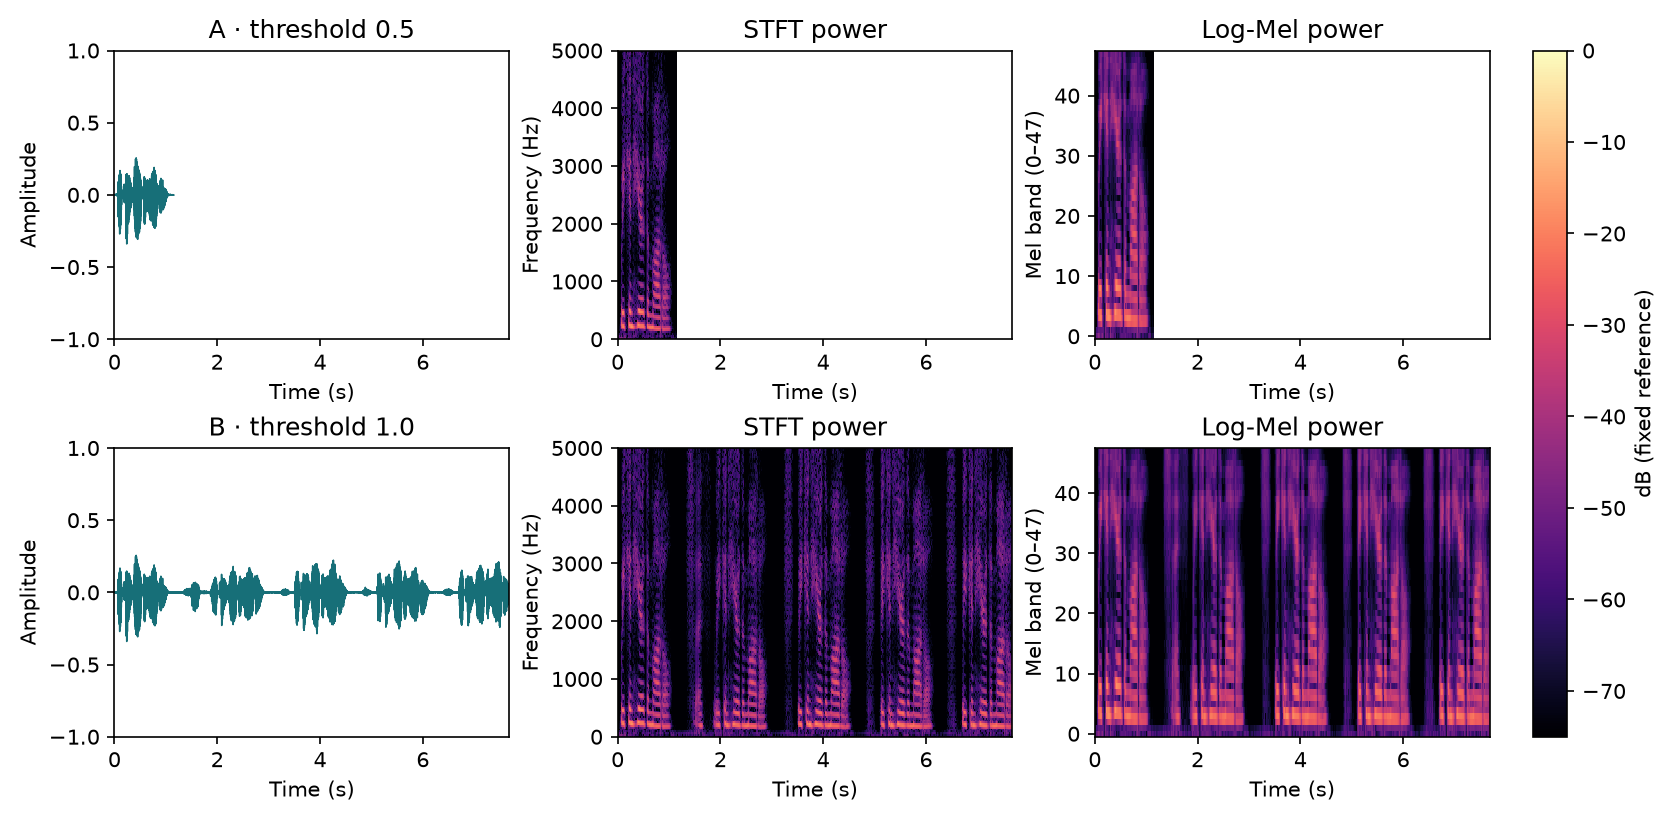


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w12a/course/notion/w12a/assets/03-voice.png)


In [ ]:
def stop_rule(score, threshold=.5):
    """현재 SpeechT5의 합산 stop score를 기준값과 비교한다. 확률 자체가 아님.

    score는 reduction_factor개 sigmoid 출력의 합, 기본 r=2이면0..2.
    비교는 >=. 이 함수를 실제 decode loop에 전달하여 수정이 결과에 반영된다.
    """
    return bool(float(score) >= float(threshold))


In [ ]:
def decode_speecht5(model, input_ids, speaker_embedding, threshold=.5, max_steps=240, stop_fn=stop_rule):
    """One-example actual autoregressive Mel loop, exposing every stop decision.

    Input IDs (1,L), speaker (1,512); output Mel (frames,80), trace/list.
    max_steps is decoder iterations, each emitting reduction_factor frames.
    SpeechT5 prenet uses dropout during inference; reset seed when comparing.
    stop score is SUM of r sigmoid outputs (r=2), not a single probability.
    This educational batch=1 path omits beam/attention/batched stopping.
    """
    if input_ids.ndim!=2 or input_ids.shape[0]!=1: raise ValueError('Single example only')
    if not 1<=int(max_steps)<=240: raise ValueError('max_steps must be 1..240')
    mask=(input_ids!=model.config.pad_token_id).int()
    hidden=model.speecht5.encoder(input_values=input_ids,attention_mask=mask,return_dict=True).last_hidden_state
    r=model.config.reduction_factor; m=model.config.num_mel_bins
    sequence=hidden.new_zeros(1,1,m); past=None; spectra=[]; trace=[]
    for step in range(1,int(max_steps)+1):
        pre=model.speecht5.decoder.prenet(sequence,speaker_embedding)
        out=model.speecht5.decoder.wrapped_decoder(hidden_states=pre[:,-1:],attention_mask=None,
            encoder_hidden_states=hidden,encoder_attention_mask=mask,
            past_key_values=past,use_cache=True,return_dict=True)
        last=out.last_hidden_state.squeeze(1); past=out.past_key_values
        spectrum=model.speech_decoder_postnet.feat_out(last).view(1,r,m)
        spectra.append(spectrum)
        sequence=torch.cat((sequence,spectrum[:,-1:,:]),dim=1)
        probabilities=torch.sigmoid(model.speech_decoder_postnet.prob_out(last))
        score=float(probabilities.sum())
        stopped=bool(stop_fn(score,threshold))
        trace.append(dict(step=step,frames=step*r,score=score,components=probabilities[0].tolist(),
                          reason='threshold' if stopped else ('limit' if step==int(max_steps) else 'continue')))
        if stopped: break
    mel=model.speech_decoder_postnet.postnet(torch.cat(spectra,dim=1))[0]
    return mel,trace


In [ ]:
from luna_genai.sound_studio import speech_clip
clips = []
records = []
for limit in (.5, 1.0):
    result = speech_clip(threshold=limit, decoder_fn=decode_speecht5, stop_fn=stop_rule)
    records.append(result)
    clips.append(present(f"지금 생성 · threshold {limit}", f"speech-{limit}.wav",
                         result["waveform"], result["sampling_rate"]))
    print("종료 단계", result["trace"][-1]["step"],
          "종료 이유", result["trace"][-1]["reason"])
compare(clips)


### A2 · 종료 줄을 바꾸기
문장은 그대로 두고 종료 임계값을 하나 더 시험합니다. 반복 구간의 시작·끝을 대략 기록하세요. 종료점수 1.1을 어떤 말로 설명할 수 있나요?


## 3. 음악을 지금 생성하고 악기만 바꾸기

MusicGen은 문장을 조건으로 압축된 음향 토큰을 예측하고 코덱 디코더로 파형을 복원합니다. 여기서는 시드, 토큰 예산, 모델을 고정합니다. 생성 모델의 첫 다운로드에는 시간이 걸립니다. 미리 들어 볼 학생은 위 오프라인 페이지의 **사전 생성** 피아노·기타를 사용하세요.


In [ ]:
def music_prompt(instrument):
    return f"A bright {instrument} melody at a steady tempo"

def music_clip(instrument, seed=7, max_tokens=100, *, prompt_fn=music_prompt):
    import torch

    if not 32 <= max_tokens <= 256:
        raise ValueError("Use a token budget of 32–256.")
    processor, model = load_music()
    prompt = prompt_fn(instrument)
    inputs = processor(text=[prompt], padding=True, return_tensors="pt")
    torch.manual_seed(seed)
    with torch.inference_mode():
        generated = model.generate(**inputs, do_sample=True, guidance_scale=3,
                                   max_new_tokens=max_tokens)
    samples = generated[0, 0].cpu().numpy()
    if not np.all(np.isfinite(samples)) or np.max(np.abs(samples)) < 1e-4:
        raise RuntimeError("MusicGen did not return playable audio.")
    return samples, model.config.audio_encoder.sampling_rate, prompt


In [ ]:
music_results = []
for instrument in ("piano", "acoustic guitar"):
    samples, rate, prompt = music_clip(instrument, prompt_fn=music_prompt)
    print(prompt)
    music_results.append(present("지금 생성 · " + instrument,
                                 "new-" + instrument.split()[-1] + ".wav", samples, rate))
compare(music_results, window=1024, hop=256)
diffusion_signal, diffusion_rate = read_wav(ASSET.joinpath("diffusion.wav"))
display(Audio(filename=str(ASSET.joinpath("diffusion.wav")), embed=True))
print("AudioDiffusion 사전 생성 · 텍스트 조건 없는10단계 실행 기록")


### A3 · 축제 팀의 선택
두 생성 결과 중 어느 쪽이 오프닝에 어울리나요? 귀로 들은 차이 한 가지와 스펙트로그램에서 보이는 차이 한 가지를 제시하세요. 바꾼 조건과 고정한 조건을 나눠 기록하세요.


## 4. 마지막 수정이 앱에서 들리나요?

위에서 정의한 함수를 앱에 그대로 연결합니다. 특히 `festival_tone`에서 배음의 위상이나 세기를 바꿨다면 이 셀도 다시 실행하세요. 이어 **효과음 만들기**를 누르거나 노트북에서 같은 콜백의 결과를 듣습니다. 브라우저 앱을 열려면 아래 마지막 줄의 주석을 지웁니다.


In [ ]:
app = build_studio(sound_fn=festival_tone, analysis_fn=classroom_stft,
                   stop_fn=stop_rule, decoder_fn=decode_speecht5, prompt_fn=music_prompt)
wav_path, plot, download_path, details = app.w12a_callbacks["effect"](440, .25, 512)
display(Audio(filename=wav_path, embed=True))
show_plot(plot)
print(details)
# app.launch(share=IN_COLAB, inline=False, prevent_thread_lock=True)
# Colab에서 파일 링크가 제한되면 왼쪽 파일 메뉴 또는 files.download(wav_path)를 사용합니다.


In [ ]:
rendered, rendered_rate = read_wav(wav_path)
assert wav_path == download_path and rendered_rate == 16000
assert np.array_equal(rendered, tone_a[1])
assert all(np.max(abs(record["waveform"])) > .01 for record in records)
assert records[1]["mel"].shape[0] > records[0]["mel"].shape[0]
assert music_results[0][2] == music_results[1][2] == 32000
assert np.max(abs(music_results[0][1]-music_results[1][1])) > .001
changed = build_studio(sound_fn=lambda frequency, overtone: festival_tone(frequency*1.5, overtone))
changed_path, changed_plot, _, _ = changed.w12a_callbacks["effect"](440, .25, 512)
edited, fs = read_wav(changed_path)
_, hz, power = classroom_stft(edited, fs, 1024, 128)
assert not np.array_equal(edited, rendered)
assert abs(hz[np.argmax(power.mean(axis=1))]-660) < 16
assert len(changed_plot.axes) == 4
print("W12A_AUDIO_RUNTIME_PASS", [len(c[1])/c[2] for c in clips],
      [len(c[1])/c[2] for c in music_results])
